In [97]:
import numpy as np
import matplotlib.pyplot as plt

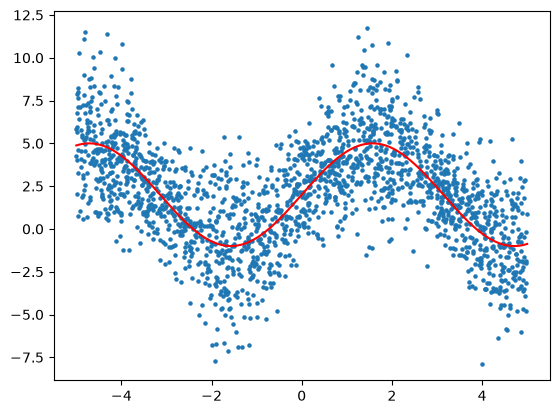

In [147]:
rng = np.random.default_rng(0)
N = 2000
H = 32
LR = 0.05
T = 60000

y_f = lambda x: m*np.sin(x)+y0

m_t, y0_t = (3, 2)
m, y0 = rng.normal(m_t, rng.uniform(0, 3), N), rng.normal(y0_t, rng.uniform(0, 5), N)

x = rng.uniform(-5, 5, N).reshape(1, N)
y = y_f(x).reshape(1, N)
x_test = np.linspace(-5, 5, N).reshape(1, N)


plt.scatter(x.ravel(), y.ravel(), s=5)
plt.plot(x_test.ravel(), m_t*np.sin(x_test).ravel()+y0_t, 'r')
plt.show()

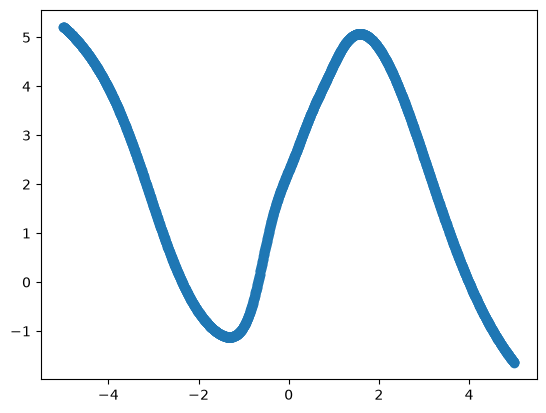

In [148]:
LR = 0.0005

x_test = np.linspace(-5, 5, N).reshape(1, N)

W1 = rng.normal(0, np.sqrt(2), (H, 1))
b1 = rng.uniform(-3, 3, (H, 1))
W2 = rng.normal(0, np.sqrt(2 / H), (1, H))
b2 = rng.uniform(-3, 3, (1, 1))

def fwd_pass(input, W1, W2, b1, b2):
    z1 = W1 @ input + b1
    a = np.tanh(z1)
    z2 = W2 @ a + b2
    return z2, z1, a

def mse_deriv(yhat, yt):
    return -1 * 2/N * (yt - yhat)

def back_prop(xin, yt, z1, z2, a, W2):
    dz2 = mse_deriv(z2, yt)
    dW2 = dz2 @ a.T
    da = W2.T @ dz2
    db2 = dz2.sum(axis=1, keepdims=True)
    dz1 = (1 - a**2) * da
    dW1 = dz1 @ xin.T
    db1 = dz1.sum(axis=1, keepdims=True)
    return dW1, dW2, db1, db2

def adjust(xin, yt, W1, W2, b1, b2, z1, z2, a):
    dW1, dW2, db1, db2 = back_prop(xin, yt, z1, z2, a, W2)
    W1 -= LR * dW1
    b1 -= LR * db1
    W2 -= LR * dW2
    b2 -= LR * db2

def learn(xin, yt, W1, W2, b1, b2, epochs):
    for _ in range(epochs):
        z2, z1, a = fwd_pass(xin, W1, W2, b1, b2)
        adjust(xin, yt, W1, W2, b1, b2, z1, z2, a)

# Train directly on raw x and y
learn(x, y, W1, W2, b1, b2, T)

# Predict directly on raw x_test (no un-normalizing needed)
y_pred = fwd_pass(x_test, W1, W2, b1, b2)[0]

plt.scatter(x_test.ravel(), y_pred.ravel())

In [124]:
import numpy as np
import itertools
import time

m_t, y0_t = (3, 2)
def y_clean(x_in):
    return m_t * x_in + y0_t

x_test = np.linspace(-5, 5, 500).reshape(1, 500)
y_true_clean = y_clean(x_test)

def run_experiment(N, H, LR, T, seed=0):
    rng = np.random.default_rng(seed)
    
    m = rng.normal(m_t, 1.5, N)
    y0 = rng.normal(y0_t, 5.0, N)
    x = rng.uniform(-5, 5, (1, N))
    y = (m * x.ravel() + y0).reshape(1, N)
    
    x_mu, x_sd = x.mean(), x.std()
    y_mu, y_sd = y.mean(), y.std()
    xn = (x - x_mu) / x_sd
    yn = (y - y_mu) / y_sd
    xt = (x_test - x_mu) / x_sd
    
    W1 = rng.normal(0, np.sqrt(2), (H, 1))
    b1 = np.zeros((H, 1))
    W2 = rng.normal(0, np.sqrt(2 / H), (1, H))
    b2 = np.zeros((1, 1))
    
    t0 = time.perf_counter()
    for _ in range(T):
        z1 = W1 @ xn + b1
        a = np.maximum(0, z1)
        z2 = W2 @ a + b2
        
        dz2 = (-2 / N) * (yn - z2)
        dW2 = dz2 @ a.T
        da = W2.T @ dz2
        db2 = dz2.sum(axis=1, keepdims=True)
        dz1 = (z1 > 0) * da
        dW1 = dz1 @ xn.T
        db1 = dz1.sum(axis=1, keepdims=True)
        
        W1 -= LR * dW1
        b1 -= LR * db1
        W2 -= LR * dW2
        b2 -= LR * db2
        
    elapsed = time.perf_counter() - t0
    
    z1_t = W1 @ xt + b1
    y_pred = (W2 @ np.maximum(0, z1_t) + b2) * y_sd + y_mu
    
    if not np.isfinite(y_pred).all():
        return np.inf, elapsed
        
    clean_mse = np.mean((y_true_clean - y_pred) ** 2)
    return clean_mse, elapsed

grid = {
    "N":  [100, 500, 2000],
    "H":  [4, 16, 32],
    "LR": [0.01, 0.05, 0.1],
    "T":  [600, 5000]
}

results = []
for N, H, LR, T in itertools.product(grid["N"], grid["H"], grid["LR"], grid["T"]):
    mse, dt = run_experiment(N, H, LR, T)
    results.append((mse, dt, N, H, LR, T))

results.sort(key=lambda r: r[0])

print(f"{'Rank':<5} {'Clean MSE':<12} {'Time(s)':<9} {'N':<6} {'H':<5} {'LR':<7} {'T':<7}")
print("-" * 55)
for rank, (mse, dt, N, H, LR, T) in enumerate(results[:10], 1):
    print(f"{rank:<5} {mse:<12.5f} {dt:<9.3f} {N:<6} {H:<5} {LR:<7} {T:<7}")

Rank  Clean MSE    Time(s)   N      H     LR      T      
-------------------------------------------------------
1     0.05380      0.083     2000   16    0.01    600    
2     0.05629      0.163     2000   32    0.05    600    
3     0.05907      0.164     2000   32    0.01    600    
4     0.06618      0.090     2000   16    0.1     600    
5     0.07128      1.407     2000   32    0.01    5000   
6     0.08152      0.083     2000   16    0.05    600    
7     0.09607      0.754     2000   16    0.01    5000   
8     0.10287      0.719     2000   16    0.05    5000   
9     0.10640      0.225     2000   4     0.05    5000   
10    0.11500      1.394     2000   32    0.05    5000   
